# 03 – Census Data

Loads 2021 Census data from Statistics Canada and attaches it to Toronto's
dissemination areas (DAs), the smallest areas with full census statistics
(about 400–700 people each).

**Data sources**
- 2021 Census Boundary Files: dissemination areas, cartographic version
  (land only, so Lake Ontario is excluded)
- 2021 Census Profile: comprehensive download, Ontario DAs

**Steps**
1. Select Toronto DAs with a spatial join (each DA's interior point must fall
   inside the city boundary), so the same code works for other cities.
2. Read the 55M-row census file in chunks and keep only Toronto DAs and 7 statistics.
3. Reshape from long format (one row per statistic) to wide (one row per DA).
4. Add young-adult population (ages 15–34) and its share of total population.

**Checks**
- 3,743 DAs covering 631 km² of land (matches Toronto's official land area)
- Total population of 2,794,356 (matches the official 2021 count)
- 68 DAs have suppressed income, which Statistics Canada does for privacy in
  areas with few residents.

**Output:** `data/processed/toronto_das_census.gpkg`

In [1]:
import pandas as pd
import geopandas as gpd

das = gpd.read_file("../data/raw/boundaries/lda_000b21a_e.shp")

print("Number of dissemination areas in Canada:", len(das))
print("CRS:", das.crs)
das.head()

Number of dissemination areas in Canada: 57932
CRS: EPSG:3347


,DAUID,DGUID,LANDAREA,PRUID,geometry
0,10010165,2021S051210010165,0.3817,10,"POLYGON ((8978199.943 2146681.889, 8978191.283..."
1,10010166,2021S051210010166,0.0954,10,"POLYGON ((8978655.237 2146599.654, 8978545.646..."
2,10010167,2021S051210010167,0.1265,10,"POLYGON ((8978582.477 2146647.18, 8978545.486 ..."
3,10010168,2021S051210010168,0.1911,10,"POLYGON ((8978846.749 2147522.749, 8978855.369..."
4,10010169,2021S051210010169,0.0662,10,"POLYGON ((8978347.594 2146972.786, 8978272.194..."


In [2]:
census_path = "../data/raw/census/98-401-X2021006_English_CSV_data_Ontario.csv"

# Only read the first 5 rows, since the full file is huge
preview = pd.read_csv(census_path, nrows=5, encoding="latin-1")

print(preview.columns.tolist())
preview.head()

['CENSUS_YEAR', 'DGUID', 'ALT_GEO_CODE', 'GEO_LEVEL', 'GEO_NAME', 'TNR_SF', 'TNR_LF', 'DATA_QUALITY_FLAG', 'CHARACTERISTIC_ID', 'CHARACTERISTIC_NAME', 'CHARACTERISTIC_NOTE', 'C1_COUNT_TOTAL', 'SYMBOL', 'C2_COUNT_MEN+', 'SYMBOL.1', 'C3_COUNT_WOMEN+', 'SYMBOL.2', 'C10_RATE_TOTAL', 'SYMBOL.3', 'C11_RATE_MEN+', 'SYMBOL.4', 'C12_RATE_WOMEN+', 'SYMBOL.5']


,CENSUS_YEAR,DGUID,ALT_GEO_CODE,GEO_LEVEL,GEO_NAME,TNR_SF,TNR_LF,DATA_QUALITY_FLAG,CHARACTERISTIC_ID,CHARACTERISTIC_NAME,...,C2_COUNT_MEN+,SYMBOL.1,C3_COUNT_WOMEN+,SYMBOL.2,C10_RATE_TOTAL,SYMBOL.3,C11_RATE_MEN+,SYMBOL.4,C12_RATE_WOMEN+,SYMBOL.5
0,2021,2021A000011124,1,Country,Canada,3.1,4.3,20000,1,"Population, 2021",...,NaN,...,NaN,...,NaN,...,NaN,...,NaN,...
1,2021,2021A000011124,1,Country,Canada,3.1,4.3,20000,2,"Population, 2016",...,NaN,...,NaN,...,NaN,...,NaN,...,NaN,...
2,2021,2021A000011124,1,Country,Canada,3.1,4.3,20000,3,"Population percentage change, 2016 to 2021",...,NaN,...,NaN,...,5.2,NaN,NaN,...,NaN,...
3,2021,2021A000011124,1,Country,Canada,3.1,4.3,20000,4,Total private dwellings,...,NaN,...,NaN,...,NaN,...,NaN,...,NaN,...
4,2021,2021A000011124,1,Country,Canada,3.1,4.3,20000,5,Private dwellings occupied by usual residents,...,NaN,...,NaN,...,NaN,...,NaN,...,NaN,...


Toronto DAs: 3743
Land area: 631 km²
All start with 3520: True


<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

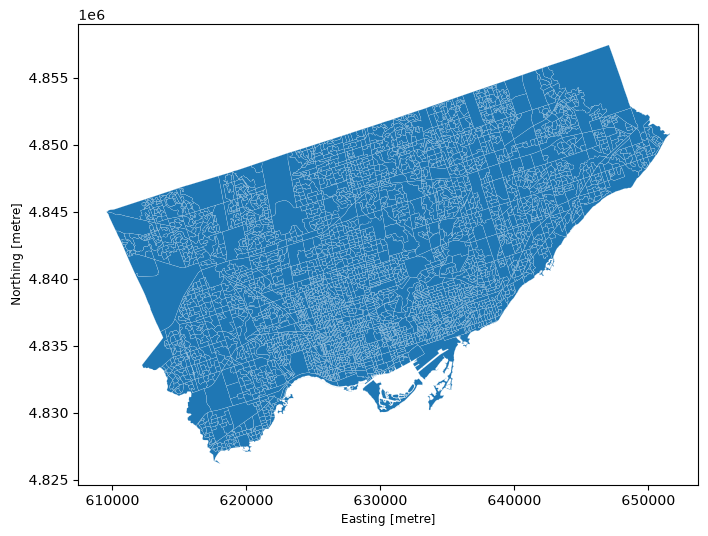

In [3]:
city = gpd.read_file("../data/processed/city_boundary.gpkg")

# Convert the DAs to the same coordinate system as our city boundary
das_utm = das.to_crs(epsg=32617)

# Keep DAs whose interior point falls inside the city
points = das_utm.copy()
points["geometry"] = das_utm.representative_point()
inside = gpd.sjoin(points, city[["geometry"]], predicate="within")

toronto_das = das_utm[das_utm["DAUID"].isin(inside["DAUID"])].copy()

print("Toronto DAs:", len(toronto_das))
print("Land area:", round(toronto_das["LANDAREA"].sum()), "km²")
print("All start with 3520:", toronto_das["DAUID"].str.startswith("3520").all())

toronto_das.plot(figsize=(8, 8), edgecolor="white", linewidth=0.1)

In [4]:
# The first area in the file has every statistic, so ~3,000 rows covers the full list
chars = pd.read_csv(
    census_path, nrows=3000, encoding="latin-1",
    usecols=["CHARACTERISTIC_ID", "CHARACTERISTIC_NAME"],
).drop_duplicates("CHARACTERISTIC_ID")

print("Total statistics available:", len(chars))

def find(keyword):
    return chars[chars["CHARACTERISTIC_NAME"].str.contains(keyword, case=False, regex=False)]

for kw in ["Population, 2021", "Population density", "Median total income of household",
           "15 to 19 years", "20 to 24 years", "25 to 29 years", "30 to 34 years"]:
    print(f"--- {kw} ---")
    print(find(kw).to_string(index=False))
    print()

Total statistics available: 2631
--- Population, 2021 ---
 CHARACTERISTIC_ID CHARACTERISTIC_NAME
                 1    Population, 2021

--- Population density ---
 CHARACTERISTIC_ID                     CHARACTERISTIC_NAME
                 6 Population density per square kilometre

--- Median total income of household ---
 CHARACTERISTIC_ID                            CHARACTERISTIC_NAME
               243   Median total income of household in 2020 ($)

--- 15 to 19 years ---
 CHARACTERISTIC_ID CHARACTERISTIC_NAME
                14      15 to 19 years

--- 20 to 24 years ---
 CHARACTERISTIC_ID CHARACTERISTIC_NAME
                15      20 to 24 years

--- 25 to 29 years ---
 CHARACTERISTIC_ID CHARACTERISTIC_NAME
                16      25 to 29 years

--- 30 to 34 years ---
 CHARACTERISTIC_ID CHARACTERISTIC_NAME
                17      30 to 34 years



In [5]:
STAT_IDS = {
    1: "population",
    6: "pop_density",
    243: "median_hh_income",
    14: "age_15_19",
    15: "age_20_24",
    16: "age_25_29",
    17: "age_30_34",
}
toronto_ids = set(toronto_das["DAUID"])

pieces = []
for chunk in pd.read_csv(
    census_path, encoding="latin-1", chunksize=1_000_000,
    usecols=["ALT_GEO_CODE", "GEO_LEVEL", "CHARACTERISTIC_ID", "C1_COUNT_TOTAL"],
    dtype={"ALT_GEO_CODE": str},
):
    keep = chunk[
        (chunk["GEO_LEVEL"] == "Dissemination area")
        & (chunk["ALT_GEO_CODE"].isin(toronto_ids))
        & (chunk["CHARACTERISTIC_ID"].isin(STAT_IDS))
    ]
    pieces.append(keep)

census_long = pd.concat(pieces)
print("Rows kept:", len(census_long))

Rows kept: 26201


In [6]:
census = census_long.pivot(index="ALT_GEO_CODE", columns="CHARACTERISTIC_ID",
                           values="C1_COUNT_TOTAL")
census = census.rename(columns=STAT_IDS).apply(pd.to_numeric, errors="coerce")

# Young adults (15–34) are the core customers for many specialty stores
census["age_15_34"] = census[["age_15_19", "age_20_24", "age_25_29", "age_30_34"]].sum(axis=1)
census["share_15_34"] = census["age_15_34"] / census["population"]

print("Total population:", int(census["population"].sum()))
print("Missing income values:", census["median_hh_income"].isna().sum())
census.describe().round(1)

Total population: 2794356
Missing income values: 68


CHARACTERISTIC_ID,population,pop_density,age_15_19,age_20_24,age_25_29,age_30_34,median_hh_income,age_15_34,share_15_34
count,3743.0,3743.0,3734.0,3734.0,3734.0,3734.0,3675.0,3743.0,3734.0
mean,746.6,9749.0,36.1,49.7,65.3,66.1,102566.0,216.6,0.3
std,647.4,21044.0,31.9,59.5,112.2,112.8,45185.4,288.3,0.1
min,0.0,0.0,0.0,0.0,0.0,0.0,22600.0,0.0,0.0
25%,441.0,3576.3,20.0,25.0,25.0,25.0,77500.0,105.0,0.2
50%,550.0,6138.1,30.0,35.0,40.0,40.0,95000.0,140.0,0.3
75%,788.0,9965.7,40.0,50.0,65.0,60.0,114000.0,210.0,0.3
max,9625.0,1062000.0,505.0,785.0,2140.0,2330.0,608000.0,5200.0,0.8


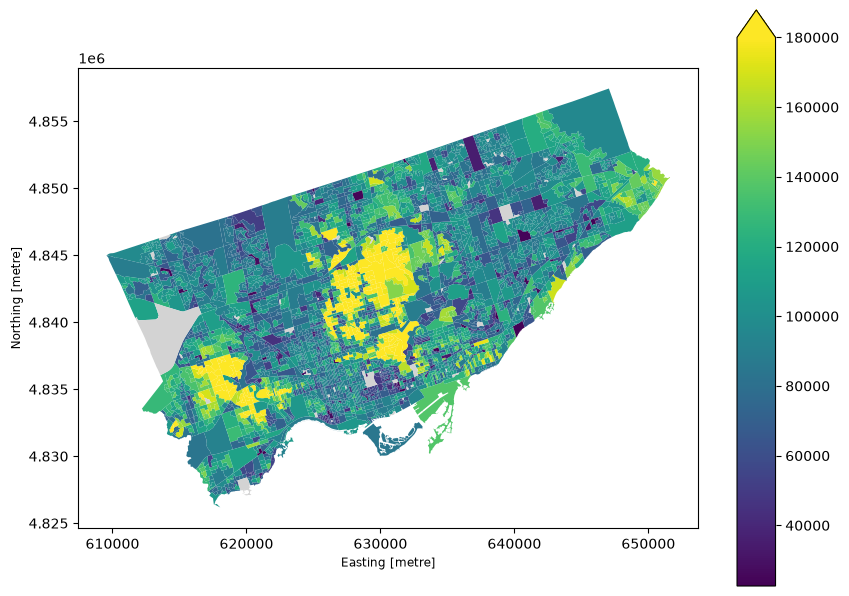

In [8]:
toronto_census = toronto_das.merge(census, left_on="DAUID", right_index=True, how="left")

vmax = toronto_census["median_hh_income"].quantile(0.95)
toronto_census.plot(column="median_hh_income", cmap="viridis", legend=True, vmax=vmax,
                    figsize=(10, 10), missing_kwds={"color": "lightgrey"})

toronto_census.to_file("../data/processed/toronto_das_census.gpkg", driver="GPKG")